# week 2: simulation results & make your own algorithm simulation

In [10]:
import numpy as np
import pandas as pd
pd.options.mode.chained_assignment = None 
import pickle

import os
from importlib import reload

import matplotlib.pyplot as plt
import matplotlib 
# import seaborn as sns
%matplotlib inline
plt.style.use('ggplot')
from matplotlib.ticker import MultipleLocator

# -----
# part 1: load competition details & visualize

In [11]:
df_comp_details = pd.read_csv('../duopoly_competition_details1.csv')
df_comp_details.fillna(0, inplace=True)
df_comp_details.head(3)

,competition_id,selling_season,selling_period,competitor_id,price_competitor,price,demand,competitor_has_capacity,calculation_duration,errors
0,3HmCSH,1,1,SaffronDolphin,56.1,66.4,0,True,0.005,0.0
1,3HmCSH,1,2,SaffronDolphin,66.4,66.4,0,True,0.006,0.0
2,3HmCSH,1,3,SaffronDolphin,66.4,66.4,0,True,0.007,0.0


#### check how many competitions (one set it 100 selling seasons) we ran against each competitor
- when two opponents are selected for a 'battle' they perform 4 competitions
- during one night you can be drawn twice to compete against the same competitor

In [12]:
df_comp_details.groupby('competitor_id').agg({
    'competition_id' : 'nunique',
    'selling_season' : ['max', 'count']
})

competition_id selling_season       
                       nunique            max  count
competitor_id                                       
AttentiveOriole              2            100  20000
SaffronDolphin               2            100  20000

In [13]:
df_comp_details['unique_selling_season_key'] = df_comp_details.apply(lambda r:
                                "%s_%s" % (r.competition_id,r.selling_season), axis=1)

df_comp_details.head(3)

,competition_id,selling_season,selling_period,competitor_id,price_competitor,price,demand,competitor_has_capacity,calculation_duration,errors,unique_selling_season_key
0,3HmCSH,1,1,SaffronDolphin,56.1,66.4,0,True,0.005,0.0,3HmCSH_1
1,3HmCSH,1,2,SaffronDolphin,66.4,66.4,0,True,0.006,0.0,3HmCSH_1
2,3HmCSH,1,3,SaffronDolphin,66.4,66.4,0,True,0.007,0.0,3HmCSH_1


# ----
# part 2: simulate a basic pricing algorithm with data from the competition details CSV

### When simulating the DPC demand algorithms based on the competition details CSV, consider the shifted time information structure
- when requested to return the price for selling period 1, we only have the information that the competitor has capacity to sell, but no demand and pricing information from the previous selling period (since there is no)
- when requesting the price for selling_period 2, the pricing function will receive the information on the prices (including the competitor's) from the last period (1) and the realized demand from the previous selling_period
- ...

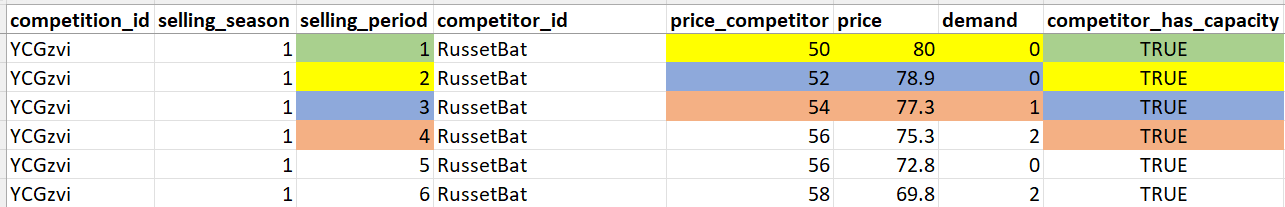

#### pre-step: delete potential exisiting 'duopoly_feedback.data'

In [14]:
if os.path.isfile('duopoly_feedback.data'):
    os.remove('duopoly_feedback.data')
    print('duopoly_feedback.data deleted')
else:
    print('duopoly_feedback.data does not exists')

duopoly_feedback.data does not exists


#### reload the pricing algo, in case you made changes

In [15]:
import sys
import os


sys.path.append(os.path.abspath('..')) 

import duopoly as duopoly
reload(duopoly)

<module 'duopoly' from 'c:\\Users\\VCB\\Documents\\BERLIN\\COURS\\learning optimization\\BHT-Learning-Optimization\\duopoly.py'>

In [16]:
df_comp_details.demand.describe()

count    40000.000000
mean         0.780400
std          0.958175
min          0.000000
25%          0.000000
50%          1.000000
75%          1.000000
max          7.000000
Name: demand, dtype: float64

### loop over the selling_period (starting at 1 with the initialization) and call the price function from your algo


In [17]:
s = 1 # first selling season
max_t = 100 # selling period until we want to run the simulation
information_dump = None
my_prices = []

# select form the competition details CSV which selling_season 
# you want to use for the simulation
id = df_comp_details['unique_selling_season_key'].unique()[10]
df_select = df_comp_details[df_comp_details.unique_selling_season_key==id]

# loop over the selling periods t
for t in np.arange(1,(max_t+1),1):
    
    print("we are in selling_period = %d" % t)

    if t <=1 :
        prices_historical = None
        demand_historical = None
    else:
        # get price info from details CSV
        prices_historical = [ my_prices, 
                              df_select[df_select.selling_period < t]['price_competitor'] ]
        prices_historical  = np.array(prices_historical)
        # get demand info from details CSV
        demand_historical  = np.array(df_select[df_select.selling_period < t]['demand'])

    # get current info if competitor can sell
    competitor_has_capacity = df_select[df_select.selling_period == t]['competitor_has_capacity'].values[0]
    
    # build input object for price algo
    request_input = {
        "current_selling_season" : s, 
        "selling_period_in_current_season" : t,
        "prices_historical_in_current_season" : prices_historical, 
        "demand_historical_in_current_season" : demand_historical, 
        "competitor_has_capacity_current_period_in_current_season" : competitor_has_capacity, 
        "information_dump": information_dump
    }
    # request price from you algo and receive (price, information_dump)
    price , information_dump = duopoly.p(**request_input)
    
    print("###")
    print("We received from the algo the following results:")
    print("price: %.2f" % price)
    print("information_dump: %s" % str(information_dump) )
    # add you price to the own prices arroy
    my_prices.append(price)

we are in selling_period = 1
###
We received from the algo the following results:
price: 65.00
information_dump: {'sold_seats': 0, 'last_price': 65.0}
we are in selling_period = 2
###
We received from the algo the following results:
price: 65.00
information_dump: {'sold_seats': 0, 'last_price': 65.0}
we are in selling_period = 3
###
We received from the algo the following results:
price: 65.00
information_dump: {'sold_seats': 0, 'last_price': 65.0}
we are in selling_period = 4
###
We received from the algo the following results:
price: 53.75
information_dump: {'sold_seats': 0, 'last_price': 53.749997647435784}
we are in selling_period = 5
###
We received from the algo the following results:
price: 53.75
information_dump: {'sold_seats': 0, 'last_price': 53.749997647435784}
we are in selling_period = 6
###
We received from the algo the following results:
price: 53.75
information_dump: {'sold_seats': 0, 'last_price': 53.749997647435784}
we are in selling_period = 7
###
We received from th

⚠️ ATTENTION : Stock épuisé (80 sièges vendus) à la période : 97
💰 Chiffre d'affaires total : $7683.53


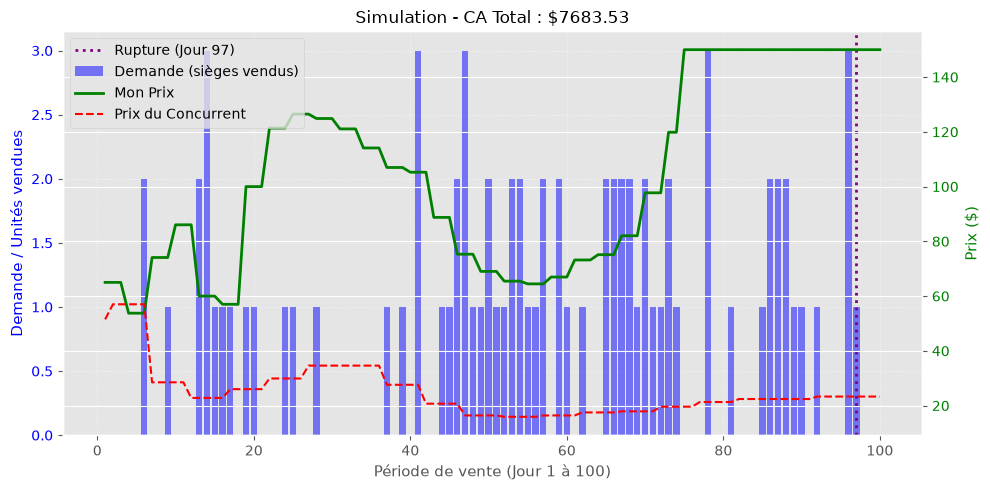

In [18]:
# 1. Construction du DataFrame de résultats
df_sim_results = pd.DataFrame({
    'selling_period': np.arange(1, len(my_prices) + 1),
    'my_price': my_prices,
    'competitor_price': df_select['price_competitor'].values[:len(my_prices)],
    'demand': df_select['demand'].values[:len(my_prices)]
})

# 2. Calcul des ventes cumulées et du chiffre d'affaires
df_sim_results['revenue'] = df_sim_results['my_price'] * df_sim_results['demand']
df_sim_results['cum_demand'] = df_sim_results['demand'].cumsum()
total_revenue = df_sim_results['revenue'].sum()

# 3. Détection de la rupture de stock (dernier siège vendu)
sold_out_rows = df_sim_results[df_sim_results['cum_demand'] >= 80]
if not sold_out_rows.empty:
    last_seat_period = sold_out_rows['selling_period'].iloc[0]
    print(f"⚠️ ATTENTION : Stock épuisé (80 sièges vendus) à la période : {last_seat_period}")
else:
    total_sold = df_sim_results['cum_demand'].iloc[-1]
    print(f"✅ Stock géré avec succès ! Total de sièges vendus sur 100 jours : {total_sold} / 80")

print(f"💰 Chiffre d'affaires total : ${total_revenue:.2f}")

# 4. Tracé graphique
fig, ax = plt.subplots(figsize=(10, 5))

# Barres de demande
ax.bar(df_sim_results['selling_period'], df_sim_results['demand'], color='blue', alpha=0.5, width=0.8, label='Demande (sièges vendus)')
ax.set_xlabel('Période de vente (Jour 1 à 100)', size=11)
ax.set_ylabel('Demande / Unités vendues', color='blue', size=11)
ax.tick_params(axis='y', labelcolor='blue')

# Ligne verticale pour marquer la rupture de stock s'il y en a une
if not sold_out_rows.empty:
    ax.axvline(x=last_seat_period, color='purple', linestyle=':', linewidth=2, label=f'Rupture (Jour {last_seat_period})')

# Lignes de prix sur le second axe
ax2 = ax.twinx()
ax2.plot(df_sim_results['selling_period'], df_sim_results['my_price'], color='green', linewidth=2, label='Mon Prix')
ax2.plot(df_sim_results['selling_period'], df_sim_results['competitor_price'], color='red', linestyle='--', linewidth=1.5, label='Prix du Concurrent')
ax2.set_ylabel('Prix ($)', color='green', size=11)
ax2.tick_params(axis='y', labelcolor='green')

ax.set_title(f"Simulation - CA Total : ${total_revenue:.2f}", size=12)
ax.grid(True, linestyle=':', alpha=0.6)

# Légende combinée
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper left')

fig.tight_layout()
plt.show()